**Import libraries**

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_olivetti_faces

**Load the Olivetti Faces dataset**

In [2]:
faces = fetch_olivetti_faces()

print("Dataset loaded successfully!")

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to C:\Users\Pheany\scikit_learn_data
Dataset loaded successfully!


In [3]:
print(faces)

{'data': array([[0.30991736, 0.3677686 , 0.41735536, ..., 0.15289256, 0.16115703,
        0.1570248 ],
       [0.45454547, 0.47107437, 0.5123967 , ..., 0.15289256, 0.15289256,
        0.15289256],
       [0.3181818 , 0.40082645, 0.49173555, ..., 0.14049587, 0.14876033,
        0.15289256],
       ...,
       [0.5       , 0.53305787, 0.607438  , ..., 0.17768595, 0.14876033,
        0.19008264],
       [0.21487603, 0.21900827, 0.21900827, ..., 0.57438016, 0.59090906,
        0.60330576],
       [0.5165289 , 0.46280992, 0.28099173, ..., 0.35950413, 0.3553719 ,
        0.38429752]], dtype=float32), 'images': array([[[0.30991736, 0.3677686 , 0.41735536, ..., 0.37190083,
         0.3305785 , 0.30578512],
        [0.3429752 , 0.40495867, 0.43801653, ..., 0.37190083,
         0.338843  , 0.3140496 ],
        [0.3429752 , 0.41735536, 0.45041323, ..., 0.38016528,
         0.338843  , 0.29752067],
        ...,
        [0.21487603, 0.20661157, 0.2231405 , ..., 0.15289256,
         0.16528925, 0.17

In [4]:
print("Images shape:", faces.images.shape)
print("Data shape:", faces.data.shape)
print("Target shape:", faces.target.shape)

Images shape: (400, 64, 64)
Data shape: (400, 4096)
Target shape: (400,)


**How many people?**

In [5]:
number_of_people = len(np.unique(faces.target))

print("Number of people:", number_of_people)

Number of people: 40


**Look at one face**

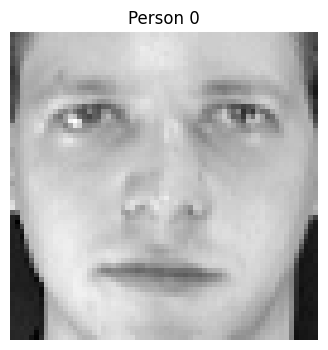

In [6]:
plt.figure(figsize=(4, 4))

plt.imshow(faces.images[0], cmap="gray")
plt.title(f"Person {faces.target[0]}")
plt.axis("off")

plt.show()

**Look at the actual pixel values**

In [7]:
print(faces.images[0])

[[0.30991736 0.3677686  0.41735536 ... 0.37190083 0.3305785  0.30578512]
 [0.3429752  0.40495867 0.43801653 ... 0.37190083 0.338843   0.3140496 ]
 [0.3429752  0.41735536 0.45041323 ... 0.38016528 0.338843   0.29752067]
 ...
 [0.21487603 0.20661157 0.2231405  ... 0.15289256 0.16528925 0.17355372]
 [0.20247933 0.2107438  0.2107438  ... 0.14876033 0.16115703 0.16528925]
 [0.20247933 0.20661157 0.20247933 ... 0.15289256 0.16115703 0.1570248 ]]


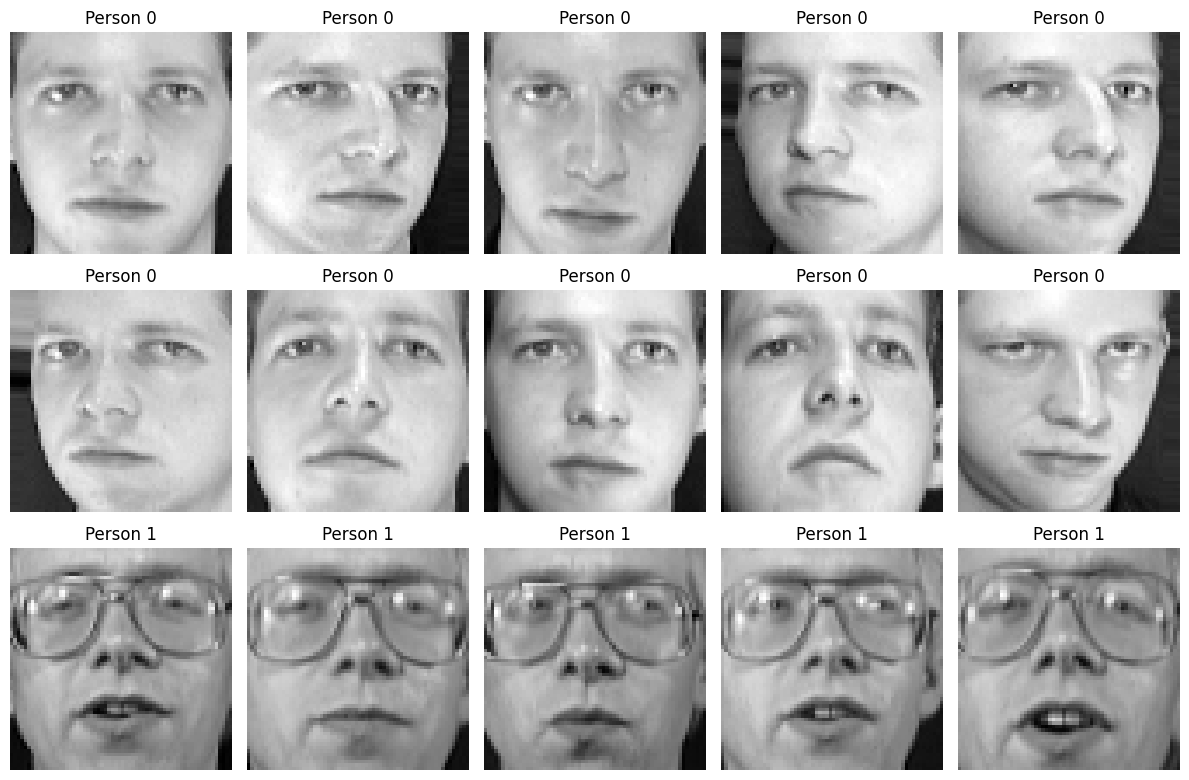

In [8]:
fig, axes = plt.subplots(3, 5, figsize=(12, 8))

for i, ax in enumerate(axes.flat):
    ax.imshow(faces.images[i], cmap="gray")
    ax.set_title(f"Person {faces.target[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

**Display one person's 10 images**

In [9]:
person_id = 0

indices = np.where(faces.target == person_id)[0]

print("Image indices:", indices)
print("Number of images:", len(indices))

Image indices: [0 1 2 3 4 5 6 7 8 9]
Number of images: 10


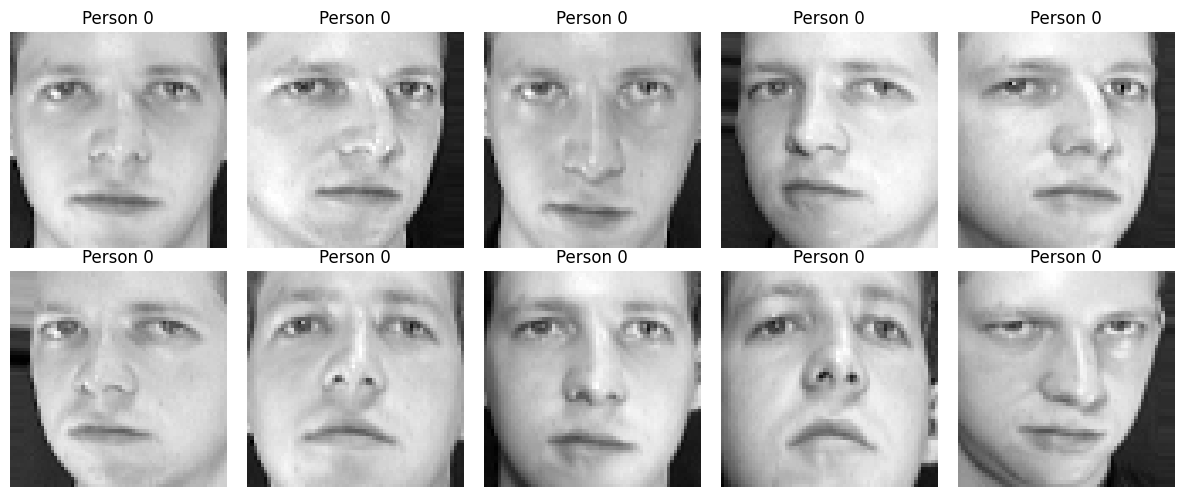

In [10]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for ax, index in zip(axes.flat, indices):
    ax.imshow(faces.images[index], cmap="gray")
    ax.set_title(f"Person {person_id}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [11]:
X = faces.data
y = faces.target

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (400, 4096)
y shape: (400,)


**Create the train/test split**

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

In [13]:
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (300, 4096)
X_test : (100, 4096)
y_train: (300,)
y_test : (100,)


**Check how many images each person has**

In [14]:
unique_train, counts_train = np.unique(y_train, return_counts=True)

for person, count in zip(unique_train, counts_train):
    print(f"Person {person}: {count} training images")

Person 0: 8 training images
Person 1: 7 training images
Person 2: 7 training images
Person 3: 7 training images
Person 4: 8 training images
Person 5: 7 training images
Person 6: 8 training images
Person 7: 7 training images
Person 8: 8 training images
Person 9: 8 training images
Person 10: 7 training images
Person 11: 7 training images
Person 12: 8 training images
Person 13: 8 training images
Person 14: 7 training images
Person 15: 8 training images
Person 16: 8 training images
Person 17: 8 training images
Person 18: 7 training images
Person 19: 8 training images
Person 20: 7 training images
Person 21: 7 training images
Person 22: 7 training images
Person 23: 7 training images
Person 24: 8 training images
Person 25: 8 training images
Person 26: 8 training images
Person 27: 8 training images
Person 28: 7 training images
Person 29: 7 training images
Person 30: 7 training images
Person 31: 8 training images
Person 32: 7 training images
Person 33: 8 training images
Person 34: 8 training im

In [15]:
unique_test, counts_test = np.unique(y_test, return_counts=True)

for person, count in zip(unique_test, counts_test):
    print(f"Person {person}: {count} testing images")

Person 0: 2 testing images
Person 1: 3 testing images
Person 2: 3 testing images
Person 3: 3 testing images
Person 4: 2 testing images
Person 5: 3 testing images
Person 6: 2 testing images
Person 7: 3 testing images
Person 8: 2 testing images
Person 9: 2 testing images
Person 10: 3 testing images
Person 11: 3 testing images
Person 12: 2 testing images
Person 13: 2 testing images
Person 14: 3 testing images
Person 15: 2 testing images
Person 16: 2 testing images
Person 17: 2 testing images
Person 18: 3 testing images
Person 19: 2 testing images
Person 20: 3 testing images
Person 21: 3 testing images
Person 22: 3 testing images
Person 23: 3 testing images
Person 24: 2 testing images
Person 25: 2 testing images
Person 26: 2 testing images
Person 27: 2 testing images
Person 28: 3 testing images
Person 29: 3 testing images
Person 30: 3 testing images
Person 31: 2 testing images
Person 32: 3 testing images
Person 33: 2 testing images
Person 34: 2 testing images
Person 35: 3 testing images
Pe

**SVM**

In [16]:
from sklearn.svm import SVC

In [17]:
svm_no_pca = SVC(kernel="rbf")

In [18]:
import time

start_time = time.time()

svm_no_pca.fit(X_train, y_train)

training_time_no_pca = time.time() - start_time

print(f"Training time: {training_time_no_pca:.4f} seconds")

Training time: 0.1897 seconds


In [19]:
start_time = time.time()

y_pred_no_pca = svm_no_pca.predict(X_test)

prediction_time_no_pca = time.time() - start_time

print(f"Prediction time: {prediction_time_no_pca:.4f} seconds")

Prediction time: 0.1389 seconds


In [20]:
from sklearn.metrics import accuracy_score

accuracy_no_pca = accuracy_score(y_test, y_pred_no_pca)

print(f"Accuracy without PCA: {accuracy_no_pca * 100:.2f}%")

Accuracy without PCA: 94.00%


In [21]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_no_pca))

              precision    recall  f1-score   support

           0       1.00      0.50      0.67         2
           1       1.00      1.00      1.00         3
           2       1.00      1.00      1.00         3
           3       1.00      0.67      0.80         3
           4       1.00      1.00      1.00         2
           5       1.00      1.00      1.00         3
           6       1.00      1.00      1.00         2
           7       0.75      1.00      0.86         3
           8       1.00      1.00      1.00         2
           9       1.00      0.50      0.67         2
          10       1.00      1.00      1.00         3
          11       1.00      1.00      1.00         3
          12       1.00      1.00      1.00         2
          13       1.00      1.00      1.00         2
          14       1.00      1.00      1.00         3
          15       0.67      1.00      0.80         2
          16       1.00      0.50      0.67         2
          17       1.00    

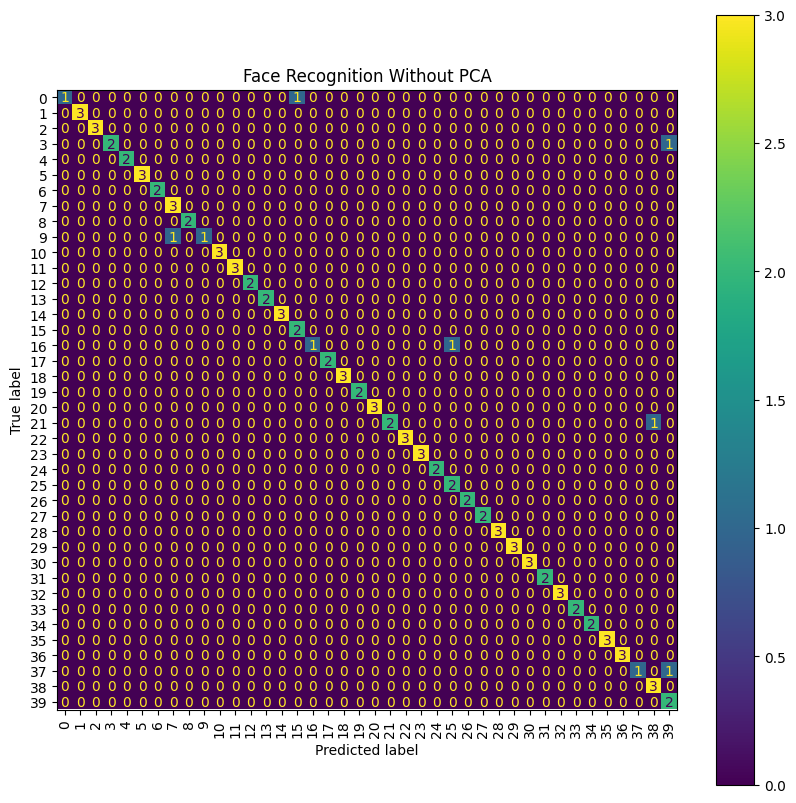

In [23]:
fig, ax = plt.subplots(figsize=(10, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_no_pca
)

disp.plot(
    ax=ax,
    xticks_rotation="vertical"
)

ax.set_title("Face Recognition Without PCA")

plt.show()

**Import PCA**

In [24]:
from sklearn.decomposition import PCA

In [25]:
pca = PCA(n_components=100, random_state=42)

In [26]:
pca.fit(X_train)

PCA(n_components=100, random_state=42)

**Transform the training and testing data**

In [27]:
X_train_pca = pca.transform(X_train)
X_test_pca = pca.transform(X_test)

In [28]:
print("Original training shape:", X_train.shape)
print("PCA training shape     :", X_train_pca.shape)

print("Original testing shape :", X_test.shape)
print("PCA testing shape      :", X_test_pca.shape)

Original training shape: (300, 4096)
PCA training shape     : (300, 100)
Original testing shape : (100, 4096)
PCA testing shape      : (100, 100)


**Check how much information PCA retained**

In [29]:
pca.explained_variance_ratio_

array([0.23316956, 0.14235124, 0.07974057, 0.05029573, 0.03624592,
       0.03200837, 0.0239427 , 0.02117932, 0.01955655, 0.01740796,
       0.01620186, 0.01512247, 0.01300883, 0.0117014 , 0.01154332,
       0.00991382, 0.00932943, 0.00832799, 0.00806397, 0.0072231 ,
       0.00702334, 0.00629368, 0.00612187, 0.00577052, 0.00573369,
       0.00558384, 0.0055658 , 0.00478644, 0.00450431, 0.00424422,
       0.00418589, 0.00395493, 0.0037255 , 0.00352604, 0.00343924,
       0.00333191, 0.00315669, 0.003073  , 0.00289893, 0.00281241,
       0.00273037, 0.00265288, 0.00256073, 0.00248502, 0.0024367 ,
       0.00235721, 0.00228855, 0.00221634, 0.00215931, 0.00210983,
       0.00206452, 0.00201137, 0.00197619, 0.00193465, 0.00186228,
       0.00185167, 0.00178312, 0.00175356, 0.00170415, 0.00164576,
       0.00162332, 0.00158144, 0.00152679, 0.00151069, 0.0014858 ,
       0.00147363, 0.0014263 , 0.00140271, 0.00136667, 0.00132761,
       0.00131669, 0.00127652, 0.00126978, 0.00122673, 0.00121

In [30]:
total_variance = np.sum(pca.explained_variance_ratio_)

print(f"Variance retained: {total_variance * 100:.2f}%")

Variance retained: 94.39%


**Visualize cumulative explained variance**

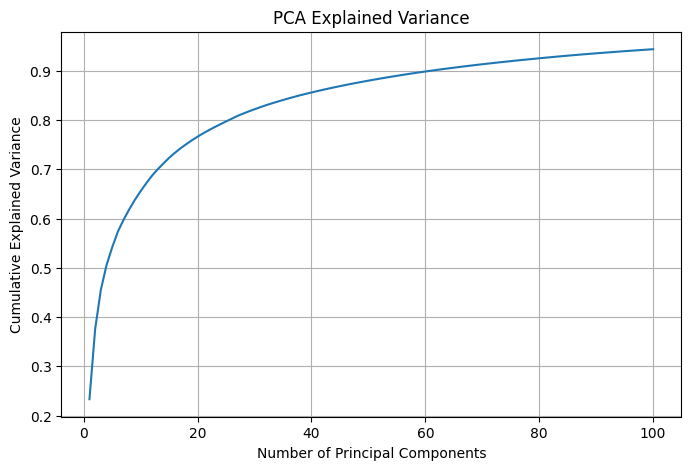

In [31]:
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Explained Variance")
plt.grid()

plt.show()

**Train the SAME SVM**

In [32]:
svm_pca = SVC(kernel="rbf")

In [33]:
import time

start_time = time.time()

svm_pca.fit(X_train_pca, y_train)

training_time_pca = time.time() - start_time

print(f"Training time with PCA: {training_time_pca:.4f} seconds")

Training time with PCA: 0.0295 seconds


**Predict the test faces**

In [34]:
start_time = time.time()

y_pred_pca = svm_pca.predict(X_test_pca)

prediction_time_pca = time.time() - start_time

print(f"Prediction time with PCA: {prediction_time_pca:.4f} seconds")

Prediction time with PCA: 0.0051 seconds


**Calculate PCA accuracy**

In [35]:
accuracy_pca = accuracy_score(y_test, y_pred_pca)

print(f"Accuracy with PCA: {accuracy_pca * 100:.2f}%")

Accuracy with PCA: 94.00%


**Make the comparison table**

In [36]:
comparison = {
    "Method": ["Without PCA", "PCA"],
    "Features": [X_train.shape[1], X_train_pca.shape[1]],
    "Accuracy": [accuracy_no_pca, accuracy_pca],
    "Training Time": [training_time_no_pca, training_time_pca],
    "Prediction Time": [prediction_time_no_pca, prediction_time_pca]
}

import pandas as pd

comparison_df = pd.DataFrame(comparison)

comparison_df

,Method,Features,Accuracy,Training Time,Prediction Time
0,Without PCA,4096,0.94,0.189743,0.138922
1,PCA,100,0.94,0.029491,0.005096


**Get the PCA components**

In [37]:
eigenfaces = pca.components_

print("Eigenfaces shape:", eigenfaces.shape)

Eigenfaces shape: (100, 4096)


**Display the first 10 eigenfaces**

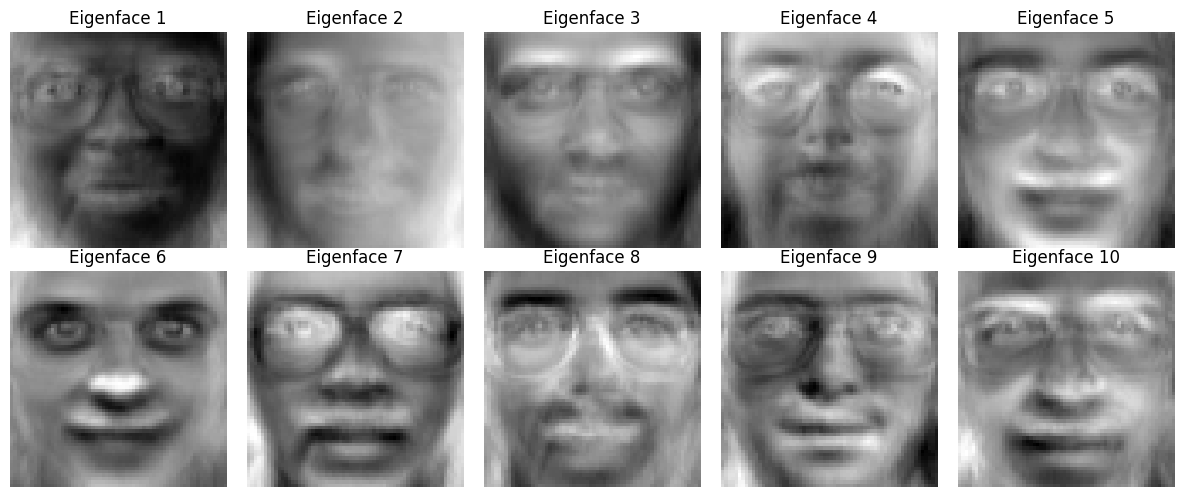

In [38]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.ravel()):
    ax.imshow(eigenfaces[i].reshape(64, 64), cmap="gray")
    ax.set_title(f"Eigenface {i+1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

**Most important eigenface**

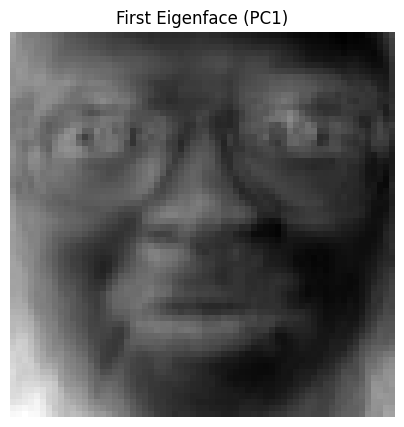

In [39]:
plt.figure(figsize=(5, 5))

plt.imshow(
    eigenfaces[0].reshape(64, 64),
    cmap="gray"
)

plt.title("First Eigenface (PC1)")
plt.axis("off")
plt.show()

**Compare the average face**

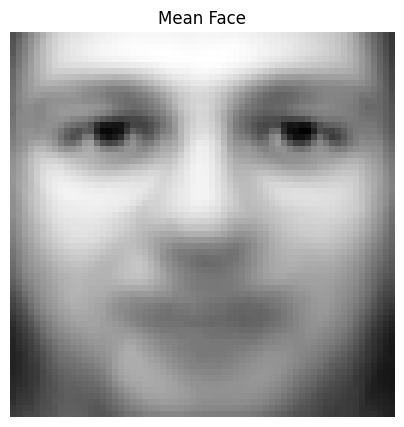

In [40]:
mean_face = pca.mean_

plt.figure(figsize=(5, 5))

plt.imshow(
    mean_face.reshape(64, 64),
    cmap="gray"
)

plt.title("Mean Face")
plt.axis("off")
plt.show()

**Test different component numbers**

In [41]:
components_list = [10, 25, 50, 100, 150, 200, 300]

results = []

for n in components_list:

    print(f"Testing {n} components...")

    # Create PCA
    pca_temp = PCA(n_components=n, random_state=42)

    # Fit PCA only on training data
    start_time = time.time()

    X_train_temp = pca_temp.fit_transform(X_train)
    X_test_temp = pca_temp.transform(X_test)

    pca_time = time.time() - start_time

    # Train SVM
    svm_temp = SVC(kernel="rbf")

    start_time = time.time()

    svm_temp.fit(X_train_temp, y_train)

    training_time = time.time() - start_time

    # Prediction
    start_time = time.time()

    y_pred_temp = svm_temp.predict(X_test_temp)

    prediction_time = time.time() - start_time

    # Accuracy
    accuracy = accuracy_score(y_test, y_pred_temp)

    # Explained variance
    variance = np.sum(pca_temp.explained_variance_ratio_)

    # Save results
    results.append([
        n,
        variance,
        accuracy,
        pca_time,
        training_time,
        prediction_time
    ])

print("Experiment completed!")

Testing 10 components...
Testing 25 components...
Testing 50 components...
Testing 100 components...
Testing 150 components...
Testing 200 components...
Testing 300 components...
Experiment completed!


**Create a results table**

In [42]:
results_df = pd.DataFrame(
    results,
    columns=[
        "Components",
        "Variance Retained",
        "Accuracy",
        "PCA Time",
        "Training Time",
        "Prediction Time"
    ]
)

results_df

,Components,Variance Retained,Accuracy,PCA Time,Training Time,Prediction Time
0,10,0.655897,0.87,0.074692,0.021713,0.006674
1,25,0.797274,0.94,0.130192,0.015797,0.006958
2,50,0.879668,0.93,0.132008,0.014723,0.000000
3,100,0.943886,0.94,0.333935,0.016029,0.016820
4,150,0.972471,0.94,0.510500,0.024049,0.000000
5,200,0.987737,0.94,0.670645,0.021749,0.000000
6,300,1.000000,0.94,0.473161,0.030728,0.010612


**Convert percentages**

In [43]:
results_df["Variance Retained (%)"] = (
    results_df["Variance Retained"] * 100
)

results_df["Accuracy (%)"] = (
    results_df["Accuracy"] * 100
)

results_df

,Components,Variance Retained,Accuracy,PCA Time,Training Time,Prediction Time,Variance Retained (%),Accuracy (%)
0,10,0.655897,0.87,0.074692,0.021713,0.006674,65.589752,87.0
1,25,0.797274,0.94,0.130192,0.015797,0.006958,79.727379,94.0
2,50,0.879668,0.93,0.132008,0.014723,0.000000,87.966797,93.0
3,100,0.943886,0.94,0.333935,0.016029,0.016820,94.388596,94.0
4,150,0.972471,0.94,0.510500,0.024049,0.000000,97.247055,94.0
5,200,0.987737,0.94,0.670645,0.021749,0.000000,98.773743,94.0
6,300,1.000000,0.94,0.473161,0.030728,0.010612,100.000000,94.0


**Plot PCA components vs accuracy**

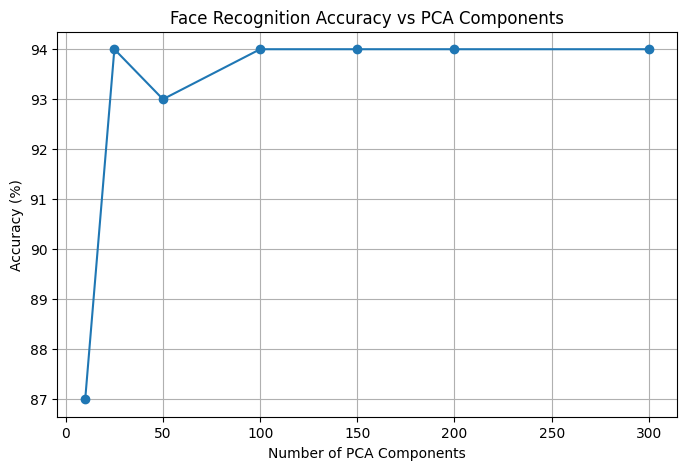

In [44]:
plt.figure(figsize=(8, 5))

plt.plot(
    results_df["Components"],
    results_df["Accuracy (%)"],
    marker="o"
)

plt.xlabel("Number of PCA Components")
plt.ylabel("Accuracy (%)")
plt.title("Face Recognition Accuracy vs PCA Components")
plt.grid()

plt.show()

**Plot components vs explained variance**

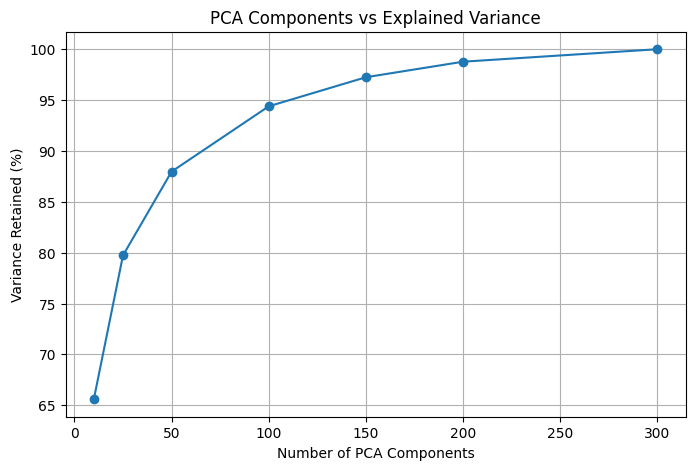

In [45]:
plt.figure(figsize=(8, 5))

plt.plot(
    results_df["Components"],
    results_df["Variance Retained (%)"],
    marker="o"
)

plt.xlabel("Number of PCA Components")
plt.ylabel("Variance Retained (%)")
plt.title("PCA Components vs Explained Variance")
plt.grid()

plt.show()

**Compare training time**

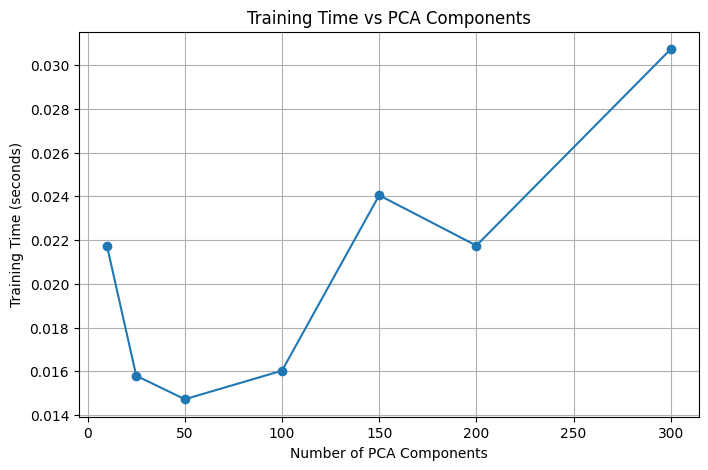

In [46]:
plt.figure(figsize=(8, 5))

plt.plot(
    results_df["Components"],
    results_df["Training Time"],
    marker="o"
)

plt.xlabel("Number of PCA Components")
plt.ylabel("Training Time (seconds)")
plt.title("Training Time vs PCA Components")
plt.grid()

plt.show()

**Compare PCA with the original 4096 features**

In [47]:
final_comparison = pd.DataFrame({
    "Method": [
        "Without PCA",
        "PCA - 10",
        "PCA - 25",
        "PCA - 50",
        "PCA - 100",
        "PCA - 150",
        "PCA - 200",
        "PCA - 300"
    ],
    
    "Features": [
        4096,
        10,
        25,
        50,
        100,
        150,
        200,
        300
    ],
    
    "Accuracy (%)": [
        accuracy_no_pca * 100,
        *results_df["Accuracy (%)"].tolist()
    ],
    
    "Training Time (s)": [
        training_time_no_pca,
        *results_df["Training Time"].tolist()
    ]
})

final_comparison

,Method,Features,Accuracy (%),Training Time (s)
0,Without PCA,4096,94.0,0.189743
1,PCA - 10,10,87.0,0.021713
2,PCA - 25,25,94.0,0.015797
3,PCA - 50,50,93.0,0.014723
4,PCA - 100,100,94.0,0.016029
5,PCA - 150,150,94.0,0.024049
6,PCA - 200,200,94.0,0.021749
7,PCA - 300,300,94.0,0.030728


**Confusion matrix without PCA**

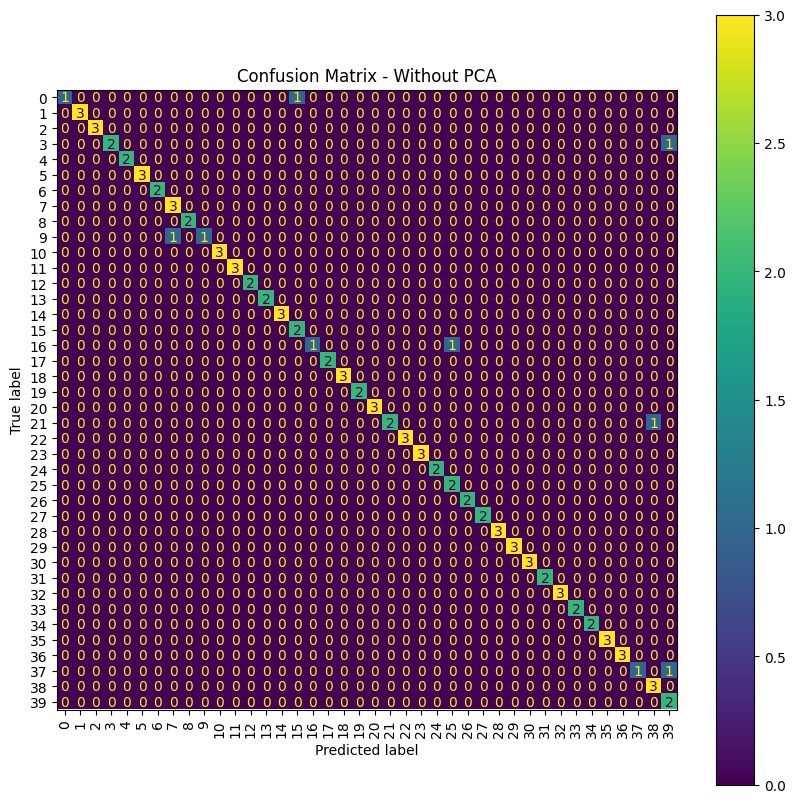

In [48]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_no_pca = confusion_matrix(y_test, y_pred_no_pca)

fig, ax = plt.subplots(figsize=(10, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_no_pca
)

disp.plot(
    ax=ax,
    xticks_rotation="vertical"
)

ax.set_title("Confusion Matrix - Without PCA")

plt.show()

**Confusion matrix with PCA**

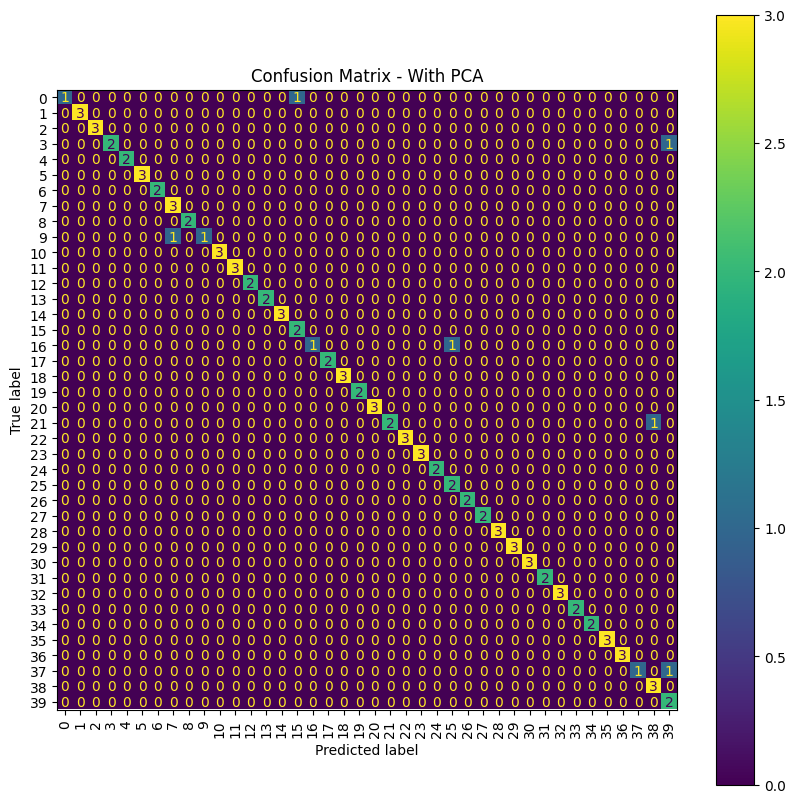

In [49]:
cm_pca = confusion_matrix(y_test, y_pred_pca)

fig, ax = plt.subplots(figsize=(10, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_pca
)

disp.plot(
    ax=ax,
    xticks_rotation="vertical"
)

ax.set_title("Confusion Matrix - With PCA")

plt.show()

**Calculate correct and incorrect predictions**

In [51]:
correct_no_pca = np.trace(cm_no_pca)
incorrect_no_pca = np.sum(cm_no_pca) - correct_no_pca

correct_pca = np.trace(cm_pca)
incorrect_pca = np.sum(cm_pca) - correct_pca

print("WITHOUT PCA")
print("Correct predictions:", correct_no_pca)
print("Incorrect predictions:", incorrect_no_pca)

print("\nWITH PCA")
print("Correct predictions:", correct_pca)
print("Incorrect predictions:", incorrect_pca)

WITHOUT PCA
Correct predictions: 94
Incorrect predictions: 6

WITH PCA
Correct predictions: 94
Incorrect predictions: 6


**Compare precision, recall and F1-score**

In [52]:
print("Classification Report - With PCA")

print(
    classification_report(
        y_test,
        y_pred_pca
    )
)

Classification Report - With PCA
              precision    recall  f1-score   support

           0       1.00      0.50      0.67         2
           1       1.00      1.00      1.00         3
           2       1.00      1.00      1.00         3
           3       1.00      0.67      0.80         3
           4       1.00      1.00      1.00         2
           5       1.00      1.00      1.00         3
           6       1.00      1.00      1.00         2
           7       0.75      1.00      0.86         3
           8       1.00      1.00      1.00         2
           9       1.00      0.50      0.67         2
          10       1.00      1.00      1.00         3
          11       1.00      1.00      1.00         3
          12       1.00      1.00      1.00         2
          13       1.00      1.00      1.00         2
          14       1.00      1.00      1.00         3
          15       0.67      1.00      0.80         2
          16       1.00      0.50      0.67     

**Overall comparison**

In [53]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision_no_pca = precision_score(
    y_test,
    y_pred_no_pca,
    average="weighted"
)

recall_no_pca = recall_score(
    y_test,
    y_pred_no_pca,
    average="weighted"
)

f1_no_pca = f1_score(
    y_test,
    y_pred_no_pca,
    average="weighted"
)


precision_pca = precision_score(
    y_test,
    y_pred_pca,
    average="weighted"
)

recall_pca = recall_score(
    y_test,
    y_pred_pca,
    average="weighted"
)

f1_pca = f1_score(
    y_test,
    y_pred_pca,
    average="weighted"
)

In [54]:
metrics_comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],

    "Without PCA": [
        accuracy_no_pca,
        precision_no_pca,
        recall_no_pca,
        f1_no_pca
    ],

    "With PCA": [
        accuracy_pca,
        precision_pca,
        recall_pca,
        f1_pca
    ]
})

metrics_comparison

,Metric,Without PCA,With PCA
0,Accuracy,0.940000,0.940000
1,Precision,0.961667,0.961667
2,Recall,0.940000,0.940000
3,F1 Score,0.938095,0.938095


**PCA Visualization (2D)**

In [55]:
pca_2d = PCA(n_components=2)

X_pca_2d = pca_2d.fit_transform(X)

In [56]:
print(X_pca_2d.shape)

(400, 2)


**Plot all faces**

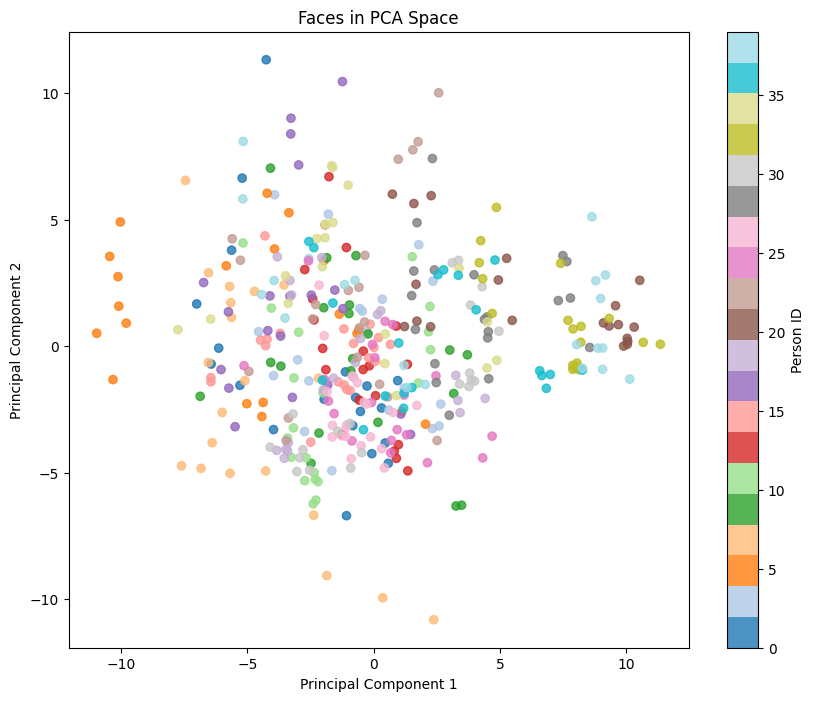

In [57]:
plt.figure(figsize=(10,8))

scatter = plt.scatter(
    X_pca_2d[:,0],
    X_pca_2d[:,1],
    c=y,
    cmap='tab20',
    alpha=0.8
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Faces in PCA Space")

plt.colorbar(label="Person ID")

plt.show()

**Show only a few people**

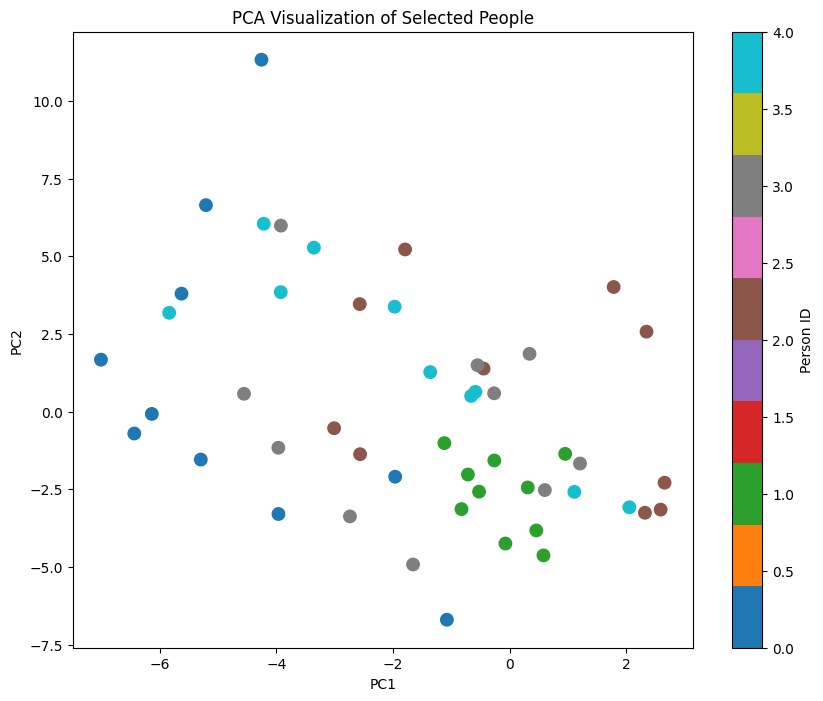

In [58]:
selected_people = [0,1,2,3,4]

mask = np.isin(y, selected_people)

plt.figure(figsize=(10,8))

scatter = plt.scatter(
    X_pca_2d[mask,0],
    X_pca_2d[mask,1],
    c=y[mask],
    cmap='tab10',
    s=80
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA Visualization of Selected People")

plt.colorbar(label="Person ID")

plt.show()

**Plot explained variance of PC1 and PC2**

In [59]:
print("PC1 variance:",
      pca_2d.explained_variance_ratio_[0]*100)

print("PC2 variance:",
      pca_2d.explained_variance_ratio_[1]*100)

PC1 variance: 23.812736570835114
PC2 variance: 13.993971049785614


In [60]:
print(
    np.sum(pca_2d.explained_variance_ratio_)*100
)

37.80670762062073
